# Feature Engineering & Preprocessing Pipeline

## Project Overview

This project implements a robust and reusable machine learning preprocessing pipeline using Python and Scikit-Learn.

The Adult Census Income dataset is used to demonstrate essential preprocessing techniques, including missing value imputation, categorical feature encoding, numerical feature scaling, and correlation analysis.

The project uses Scikit-Learn's Pipeline and ColumnTransformer to automate preprocessing operations while preventing data leakage through proper train-test splitting.

## Objectives

- Explore and understand a real-world tabular dataset.
- Handle missing numerical and categorical values.
- Apply One-Hot Encoding to categorical features.
- Standardize numerical features using StandardScaler.
- Build reusable preprocessing pipelines using ColumnTransformer.
- Perform correlation analysis.
- Identify informative features using Mutual Information.
- Ensure preprocessing parameters are learned exclusively from training data.

## Technologies Used

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn, Jupyter Notebook.

In [79]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

print("All libraries imported successfully!")

All libraries imported successfully!


In [42]:
adult = fetch_openml(
    name="adult",
    version=2,
    as_frame=True
)

df = adult.frame.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [43]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (48842, 15)

First 5 Rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K



Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week 

In [44]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
class                0
dtype: int64


In [45]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 52


In [46]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
workclass         2799
occupation        2809
native-country     857
dtype: int64

Total Missing Values: 6465


In [47]:
for col in df.select_dtypes(include="category").columns:
    print(col, ":", df[col].astype(str).unique()[:10])

workclass : <StringArray>
[         'Private',        'Local-gov',                nan,
 'Self-emp-not-inc',      'Federal-gov',        'State-gov',
     'Self-emp-inc',      'Without-pay',     'Never-worked']
Length: 9, dtype: str
education : <StringArray>
[        '11th',      'HS-grad',   'Assoc-acdm', 'Some-college',
         '10th',  'Prof-school',      '7th-8th',    'Bachelors',
      'Masters',    'Doctorate']
Length: 10, dtype: str
marital-status : <StringArray>
[        'Never-married',    'Married-civ-spouse',               'Widowed',
              'Divorced',             'Separated', 'Married-spouse-absent',
     'Married-AF-spouse']
Length: 7, dtype: str
occupation : <StringArray>
['Machine-op-inspct',   'Farming-fishing',   'Protective-serv',
                 nan,     'Other-service',    'Prof-specialty',
      'Craft-repair',      'Adm-clerical',   'Exec-managerial',
      'Tech-support']
Length: 10, dtype: str
relationship : <StringArray>
['Own-child', 'Husband', 'Not-in-

In [48]:
df = df.replace("?", np.nan)

In [49]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 52


In [50]:
print(df["class"].value_counts(dropna=False))

class
<=50K    37155
>50K     11687
Name: count, dtype: int64


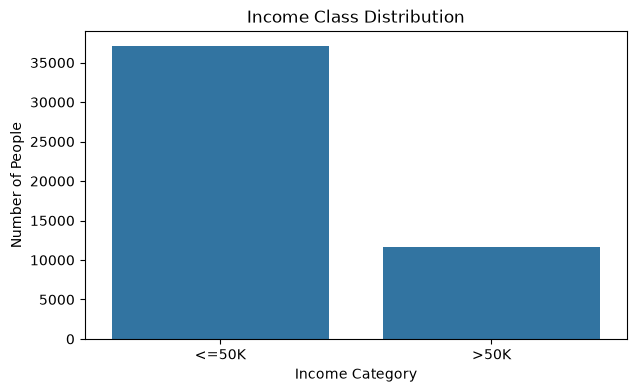

In [51]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="class")

plt.title("Income Class Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of People")

plt.show()

In [52]:
target = "class"

numerical_features = df.drop(columns=[target]).select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.drop(columns=[target]).select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [53]:
X = df.drop(columns=["class"])
y = df["class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (48842, 14)
Target Shape: (48842,)


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (39073, 14)
Testing Features: (9769, 14)
Training Target: (39073,)
Testing Target: (9769,)


In [55]:
print("Training Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))

Training Class Distribution:
class
<=50K    0.76073
>50K     0.23927
Name: proportion, dtype: float64

Testing Class Distribution:
class
<=50K    0.760672
>50K     0.239328
Name: proportion, dtype: float64


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [57]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [58]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [59]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [60]:
preprocessing_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [61]:
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

print("Training Data Preprocessed Successfully!")
print("Processed Training Shape:", X_train_processed.shape)

Training Data Preprocessed Successfully!
Processed Training Shape: (39073, 105)


In [62]:
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Testing Data Preprocessed Successfully!")
print("Processed Testing Shape:", X_test_processed.shape)

Testing Data Preprocessed Successfully!
Processed Testing Shape: (9769, 105)


In [63]:
feature_names = preprocessing_pipeline.get_feature_names_out()

print("Total Processed Features:", len(feature_names))

print("\nFirst 20 Processed Features:")
print(feature_names[:20])

Total Processed Features: 105

First 20 Processed Features:
['num__age' 'num__fnlwgt' 'num__education-num' 'num__capital-gain'
 'num__capital-loss' 'num__hours-per-week' 'cat__workclass_Federal-gov'
 'cat__workclass_Local-gov' 'cat__workclass_Never-worked'
 'cat__workclass_Private' 'cat__workclass_Self-emp-inc'
 'cat__workclass_Self-emp-not-inc' 'cat__workclass_State-gov'
 'cat__workclass_Without-pay' 'cat__education_10th' 'cat__education_11th'
 'cat__education_12th' 'cat__education_1st-4th' 'cat__education_5th-6th'
 'cat__education_7th-8th']


In [64]:
from scipy import sparse

In [65]:
if sparse.issparse(X_train_processed):
    missing_train = np.isnan(X_train_processed.data).sum()
    missing_test = np.isnan(X_test_processed.data).sum()
else:
    missing_train = np.isnan(X_train_processed).sum()
    missing_test = np.isnan(X_test_processed).sum()

print("Missing values in training data:", missing_train)
print("Missing values in testing data:", missing_test)

Missing values in training data: 0
Missing values in testing data: 0


In [66]:
num_imputer = (
    preprocessing_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["imputer"]
)

print("Learned Numerical Medians:")
print(pd.Series(
    num_imputer.statistics_,
    index=numerical_features
))

Learned Numerical Medians:
age                   37.0
fnlwgt            178134.0
education-num         10.0
capital-gain           0.0
capital-loss           0.0
hours-per-week        40.0
dtype: float64


In [67]:
correlation_matrix = X_train[numerical_features].corr()

display(correlation_matrix)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076900,0.034878,0.074203,0.058889,0.071218
fnlwgt,-0.076900,1.000000,-0.037468,-0.001570,-0.006095,-0.012779
education-num,0.034878,-0.037468,1.000000,0.121848,0.085669,0.144908
capital-gain,0.074203,-0.001570,0.121848,1.000000,-0.031748,0.081538
capital-loss,0.058889,-0.006095,0.085669,-0.031748,1.000000,0.054120
hours-per-week,0.071218,-0.012779,0.144908,0.081538,0.054120,1.000000


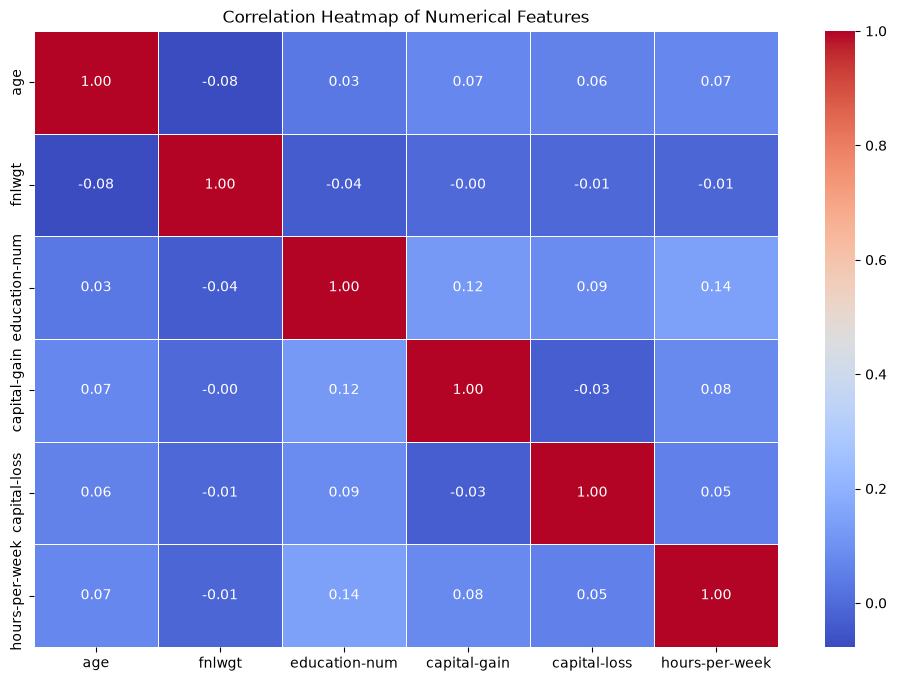

In [68]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [69]:
correlation_pairs = correlation_matrix.abs().unstack()

correlation_pairs = correlation_pairs[
    (correlation_pairs < 1) &
    (correlation_pairs >= 0.8)
]

print("Highly Correlated Feature Pairs:")
print(correlation_pairs)

Highly Correlated Feature Pairs:
Series([], dtype: float64)


In [70]:
print("Correlation Matrix:")
display(correlation_matrix)

print("\nHighly Correlated Pairs:")
print(correlation_pairs)

if correlation_pairs.empty:
    print("\nNo highly correlated feature pairs found.")

Correlation Matrix:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076900,0.034878,0.074203,0.058889,0.071218
fnlwgt,-0.076900,1.000000,-0.037468,-0.001570,-0.006095,-0.012779
education-num,0.034878,-0.037468,1.000000,0.121848,0.085669,0.144908
capital-gain,0.074203,-0.001570,0.121848,1.000000,-0.031748,0.081538
capital-loss,0.058889,-0.006095,0.085669,-0.031748,1.000000,0.054120
hours-per-week,0.071218,-0.012779,0.144908,0.081538,0.054120,1.000000



Highly Correlated Pairs:
Series([], dtype: float64)

No highly correlated feature pairs found.


In [71]:
from sklearn.feature_selection import mutual_info_classif

In [72]:
mi_scores = mutual_info_classif(
    X_train_processed,
    y_train,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": feature_names,
    "MI Score": mi_scores
})

mi_results = mi_results.sort_values(
    by="MI Score",
    ascending=False
)

display(mi_results.head(20))

/Users/ayeshamirza/Desktop/CUSTOMER_CHURN_ML/.venv/lib/python3.13/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/Users/ayeshamirza/Desktop/CUSTOMER_CHURN_ML/.venv/lib/python3.13/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/Users/ayeshamirza/Desktop/CUSTOMER_CHURN_ML/.venv/lib/python3.13/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/Users/ayeshamirza/Desktop/CUSTOMER_CHURN_ML/.venv/lib/python3.13/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering m

,Feature,MI Score
1,num__fnlwgt,0.377372
32,cat__marital-status_Married-civ-spouse,0.107539
51,cat__relationship_Husband,0.082842
3,num__capital-gain,0.081788
0,num__age,0.067948
2,num__education-num,0.063378
34,cat__marital-status_Never-married,0.063306
5,num__hours-per-week,0.041373
4,num__capital-loss,0.038161
54,cat__relationship_Own-child,0.036417


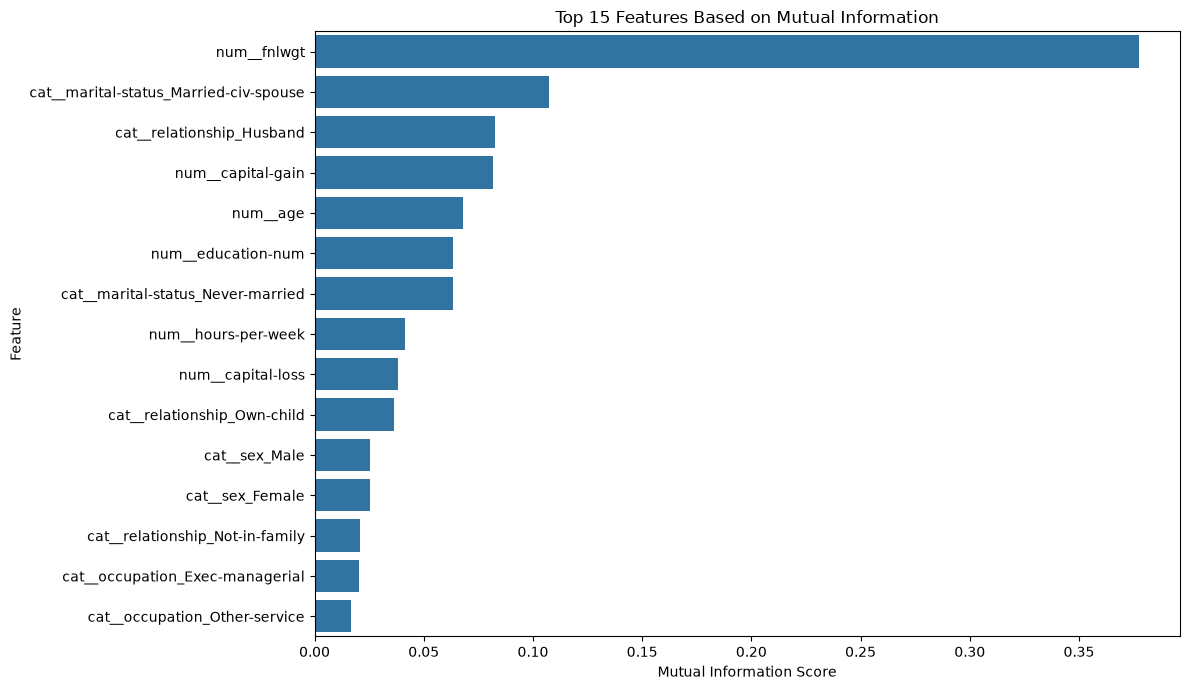

In [73]:
top_features = mi_results.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="MI Score",
    y="Feature"
)

plt.title("Top 15 Features Based on Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [74]:
print("Top 10 Most Informative Features:")

for index, row in mi_results.head(10).iterrows():
    print(f"{row['Feature']}: {row['MI Score']:.4f}")

Top 10 Most Informative Features:
num__fnlwgt: 0.3774
cat__marital-status_Married-civ-spouse: 0.1075
cat__relationship_Husband: 0.0828
num__capital-gain: 0.0818
num__age: 0.0679
num__education-num: 0.0634
cat__marital-status_Never-married: 0.0633
num__hours-per-week: 0.0414
num__capital-loss: 0.0382
cat__relationship_Own-child: 0.0364


In [75]:
from scipy import sparse

# Convert sparse matrix to dense format
X_train_dense = (
    X_train_processed.toarray()
    if sparse.issparse(X_train_processed)
    else X_train_processed
)

# Identify continuous and discrete features
discrete_mask = np.array(
    [False] * len(numerical_features) +
    [True] * (len(feature_names) - len(numerical_features))
)

print("Training Data Shape:", X_train_dense.shape)
print("Continuous Features:", np.sum(~discrete_mask))
print("Discrete Features:", np.sum(discrete_mask))

Training Data Shape: (39073, 105)
Continuous Features: 6
Discrete Features: 99


In [76]:
mi_scores = mutual_info_classif(
    X_train_dense,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": feature_names,
    "MI Score": mi_scores
})

mi_results = mi_results.sort_values(
    by="MI Score",
    ascending=False
)

display(mi_results.head(20))

,Feature,MI Score
32,cat__marital-status_Married-civ-spouse,0.107539
51,cat__relationship_Husband,0.082842
3,num__capital-gain,0.079509
2,num__education-num,0.064722
0,num__age,0.064386
34,cat__marital-status_Never-married,0.063306
4,num__capital-loss,0.039855
5,num__hours-per-week,0.038737
1,num__fnlwgt,0.037306
54,cat__relationship_Own-child,0.036417


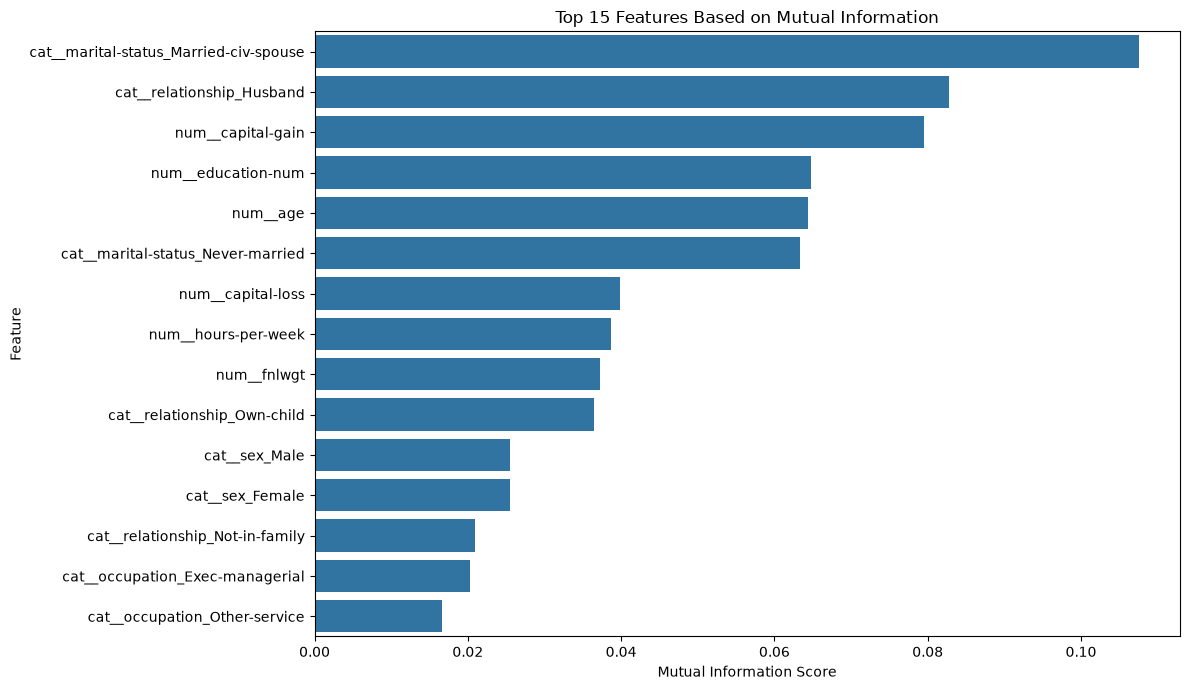

In [77]:
top_features = mi_results.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="MI Score",
    y="Feature"
)

plt.title("Top 15 Features Based on Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [78]:
print("FINAL PROJECT VERIFICATION")

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("Training Missing Values:", missing_train)
print("Testing Missing Values:", missing_test)

print("Total Features After Encoding:", len(feature_names))

print("\nTop 10 Features:")
display(mi_results.head(10))

print("\nPreprocessing pipeline:")
print(preprocessing_pipeline)

FINAL PROJECT VERIFICATION
Training Shape: (39073, 105)
Testing Shape: (9769, 105)
Training Missing Values: 0
Testing Missing Values: 0
Total Features After Encoding: 105

Top 10 Features:


,Feature,MI Score
32,cat__marital-status_Married-civ-spouse,0.107539
51,cat__relationship_Husband,0.082842
3,num__capital-gain,0.079509
2,num__education-num,0.064722
0,num__age,0.064386
34,cat__marital-status_Never-married,0.063306
4,num__capital-loss,0.039855
5,num__hours-per-week,0.038737
1,num__fnlwgt,0.037306
54,cat__relationship_Own-child,0.036417



Preprocessing pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fnlwgt',
                                                   'education-num',
                                                   'capital-gain',
                                                   'capital-loss',
                                                   'hours-per-week']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                

# Conclusion

A reusable and leak-free machine learning preprocessing pipeline was successfully implemented using Scikit-Learn.

The project handled missing values through median and most-frequent imputation, transformed categorical variables using One-Hot Encoding, and standardized numerical features using StandardScaler.

A ColumnTransformer was used to apply different preprocessing operations to numerical and categorical columns. The original dataset was divided into training and testing sets before fitting any preprocessing transformations, ensuring that information from the testing dataset did not influence the training process.

Correlation analysis was performed to examine relationships between numerical features, while Mutual Information was used to identify features containing useful information about the target variable.

The preprocessing pipeline successfully transformed the original 14 input features into 105 processed features and handled missing values without errors.

This project demonstrates a reusable approach to preparing complex tabular datasets for machine learning applications.